# 02 Outage or communication failure? A walkthrough (simulated)

Uses the committed dataset `dataset/episodes_semiurb5_seed101` (SimBench grid, 340 injected events, **SIMULATED**) and the frozen detector parameters `results/detector_params.json`. Cases are chosen by a fixed rule (the first episode of at least 10 meters with each outcome), not by hand. Per-case numbers are illustrations; measured performance is in `docs/CLAIMS_LEDGER.md`.

In [1]:
import sys, json
sys.path.insert(0, "..")  # repository root, so `shahid` imports work from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shahid import detect, evaluate, explain, grid
from shahid.world import grid_meta
plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False})
from scipy import stats
D = "../dataset/episodes_semiurb5_seed101"

## Run the frozen detector (lr_band, version 1) on the whole year

In [2]:
inputs = detect.load_inputs(D)
labels = {k: pd.read_parquet(f'{D}/labels/{k}.parquet') for k in ['episodes', 'cells']}
p = json.load(open('../results/detector_params.json'))
params = {**p['fitted'], **p['thresholds']['bayes']}
v = detect.detect(inputs, params, 'bayes')
tab = evaluate.episode_table(v, labels)
index, ids, E, A, T = detect.arrays(inputs)
pick = lambda cause, verdict: tab[(tab.cause == cause) & (tab.verdict == verdict) & (tab.n_meters >= 10)].iloc[0]
cases = {'outage, decided': pick('OUTAGE', 'OUTAGE'),
         'communication failure, decided': pick('COMMS_FAILURE', 'COMMS_FAILURE'),
         'abstained case': tab[(tab.verdict == 'UNCERTAIN') & (tab.n_meters >= 10)].iloc[0]}
pd.DataFrame(cases).T[['cause', 'start', 'end', 'n_meters', 'verdict']]

,cause,start,end,n_meters,verdict
"outage, decided",OUTAGE,2016-01-28 04:15:00,2016-01-28 07:45:00,25,OUTAGE
"communication failure, decided",COMMS_FAILURE,2016-01-23 02:00:00,2016-01-23 04:30:00,23,COMMS_FAILURE
abstained case,OUTAGE,2016-02-09 11:45:00,2016-02-09 12:45:00,31,UNCERTAIN


## Each case step by step
For each case: (1) the silent group; (2) what the transformer shows against the meters that reported on time; (3) the evidence: energy the transformer still sees beyond the reporting meters (R) and the group's expected energy (M); (4) the two hypotheses the likelihood ratio compares, R near 0 if power was lost, R near M if only data was lost; (5) the verdict and its plain-language explanation from `shahid/explain.py`.

=== outage, decided: true cause OUTAGE, 25 meters, 2016-01-28 04:15:00 to 2016-01-28 07:45:00

(1) silent group:

25

meters, onset

2016-01-28 04:15:00

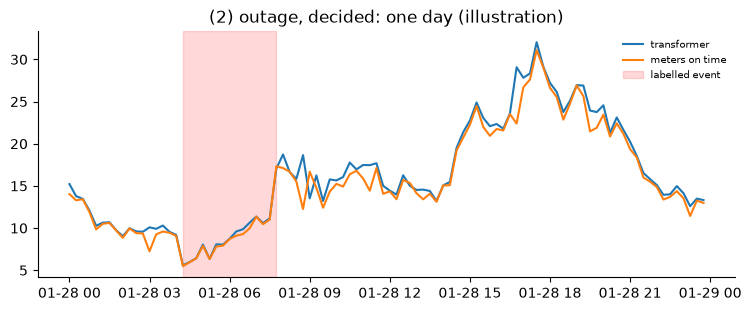

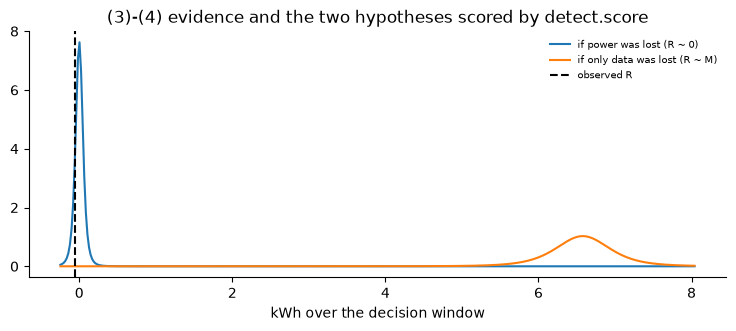

(5) verdict:

OUTAGE

| probability:

1.0

25 meters stopped reporting at 2016-01-28 04:15:00. These customers most likely lost power. Over the 2 intervals checked, these meters would normally use 6.58 kWh. The transformer still shows -0.05 kWh that no reporting meter accounts for (visible share -0.01). If power were lost, that figure should be close to zero (typical spread 0.05 kWh). If only data were lost, it should be near 6.58 (typical spread 0.37 kWh). Confidence in this cause: 1.0. The alternative considered was COMMS_FAILURE. Decided at 2016-01-28 04:45:00, 2 intervals after the meters went silent, by method bayes.

=== communication failure, decided: true cause COMMS_FAILURE, 23 meters, 2016-01-23 02:00:00 to 2016-01-23 04:30:00

(1) silent group:

22

meters, onset

2016-01-23 02:00:00

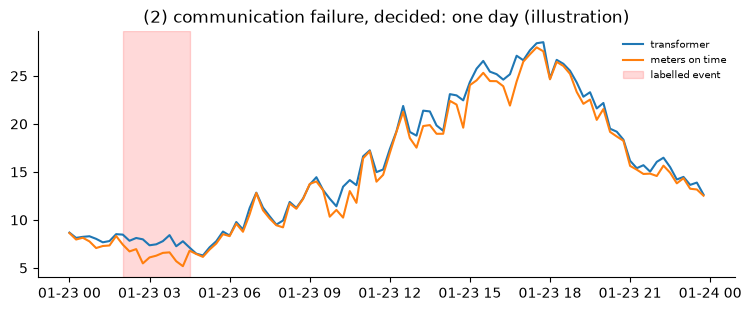

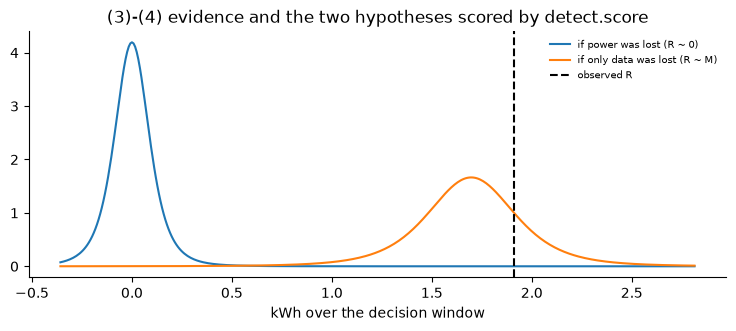

(5) verdict:

COMMS_FAILURE

| probability:

1.0

22 meters stopped reporting at 2016-01-23 02:00:00. These customers most likely still have power; only their data stopped. Over the 2 intervals checked, these meters would normally use 1.7 kWh. The transformer still shows 1.91 kWh that no reporting meter accounts for (visible share 1.13). If power were lost, that figure should be close to zero (typical spread 0.09 kWh). If only data were lost, it should be near 1.7 (typical spread 0.23 kWh). Confidence in this cause: 1.0. The alternative considered was OUTAGE. Decided at 2016-01-23 02:30:00, 2 intervals after the meters went silent, by method bayes.

=== abstained case: true cause OUTAGE, 31 meters, 2016-02-09 11:45:00 to 2016-02-09 12:45:00

(1) silent group:

29

meters, onset

2016-02-09 11:45:00

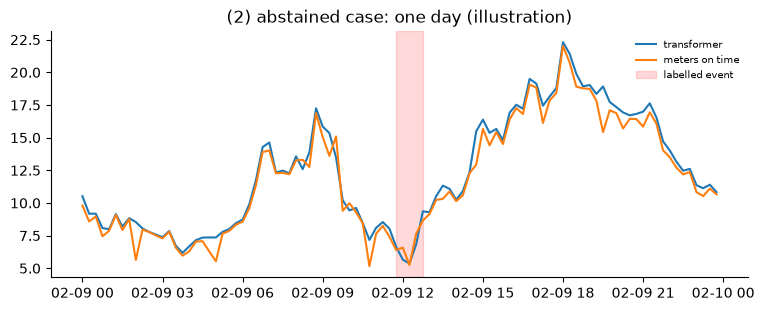

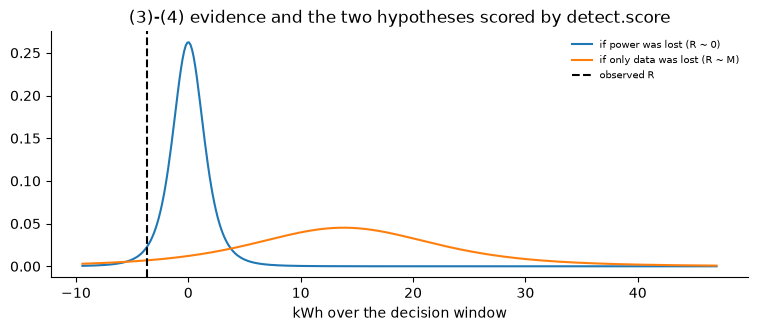

(5) verdict:

UNCERTAIN

| probability:

None

29 meters stopped reporting at 2016-02-09 11:45:00. The system cannot tell whether these customers lost power. Over the 6 intervals checked, these meters would normally use 13.82 kWh. The transformer still shows -3.71 kWh that no reporting meter accounts for (visible share -0.27). If power were lost, that figure should be close to zero (typical spread 1.43 kWh). If only data were lost, it should be near 13.82 (typical spread 8.3 kWh). Reason for not deciding: posterior 0.24 inside abstention band. Decided at 2016-02-09 13:15:00, 6 intervals after the meters went silent, by method bayes.

In [3]:
for name, c in cases.items():
    row = v.loc[int(c.verdict_row)]
    print(f'=== {name}: true cause {c.cause}, {c.n_meters} meters, {c.start} to {c.end}')
    print('(1) silent group:', len(row.meters), 'meters, onset', row.onset)
    t0 = index.get_loc(row.onset); w = np.arange(t0 // 96 * 96, t0 // 96 * 96 + 96)
    ontime = np.where(A[w] <= np.arange(len(w))[:, None] + w[0] + 1, E[w], np.nan)
    plt.plot(index[w], T[w], label='transformer'); plt.plot(index[w], np.nansum(ontime, 1), label='meters on time')
    plt.axvspan(c.start, c.end, alpha=0.15, color='red', label='labelled event')
    plt.legend(frameon=False, fontsize=7); plt.title(f'(2) {name}: one day (illustration)'); plt.show()
    x = np.linspace(min(0, row.R) - 4 * row.sd_O, max(row.M, row.R) + 4 * row.sd_C, 400)
    plt.plot(x, stats.t.pdf(x, params['t_df'], loc=0, scale=row.sd_O), label='if power was lost (R ~ 0)')
    plt.plot(x, stats.t.pdf(x, params['t_df'], loc=row.M, scale=row.sd_C), label='if only data was lost (R ~ M)')
    plt.axvline(row.R, color='k', ls='--', label='observed R')
    plt.xlabel('kWh over the decision window'); plt.legend(frameon=False, fontsize=7)
    plt.title('(3)-(4) evidence and the two hypotheses scored by detect.score'); plt.show()
    rec = explain.verdict_record(row, 'version 1 (frozen)')
    print('(5) verdict:', rec['cause'], '| probability:', rec['probability'])
    print(explain.explain(rec)); print()

The abstained case shows the method's design: when the evidence is not decisive it hands the case to a human instead of guessing (escalation table `configs/escalation.yaml`).